# pyDySP Campaign Demo

This notebook gives a compact tour of the **`Campaign`** features of **pyDySP** using a simulated shaking-table campaign. We load a folder of tests, select tests by tag and number, plot per-test values against test number, follow a resonance through the campaign with transfer functions, keep the test information in an editable CSV, and check channels across tests.

For single-test features (`Channel` and `Test`), see the [pyDySP Demo](demo.ipynb).

In [1]:
# Imports and version
import os
import tempfile
import warnings

import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

import pydysp
from pydysp import Campaign, Channel, Test

print("pyDySP version:", pydysp.__version__)

pyDySP version: 0.3.0


## Simulated campaign

We simulate 20 tests of a single-degree-of-freedom oscillator on a shaking table. Each test has an input acceleration (`Input`), a response acceleration (`Response`) and a displacement transducer (`LVDT`). The campaign mixes **hammer** tests, low-amplitude **white-noise** tests and stronger **record** (earthquake-like) tests. Every record test "damages" the oscillator a little, so its natural frequency slowly drops from 8 Hz, and leaves a small residual displacement. Test 12 was run but not recorded, so the numbering has a gap.

The tests are written as CSV files into a temporary folder, so nothing is left in the repository. In practice, these would be the files from the data acquisition system.

In [2]:
# Simulation settings and the test plan (number, kind, amplitude in g)
fs = 200.0
dt = 1.0 / fs
t = np.arange(0.0, 20.0, dt)
rng = np.random.default_rng(2026)

plan = [
    (1, "hammer", 0.5), (2, "white-noise", 0.03), (3, "record", 0.05),
    (4, "white-noise", 0.03), (5, "record", 0.10), (6, "white-noise", 0.03),
    (7, "record", 0.15), (8, "white-noise", 0.03), (9, "hammer", 0.5),
    (10, "record", 0.20), (11, "white-noise", 0.03),
    # test 12 was run but not recorded
    (13, "record", 0.25), (14, "white-noise", 0.03), (15, "record", 0.30),
    (16, "white-noise", 0.03), (17, "hammer", 0.5), (18, "record", 0.35),
    (19, "white-noise", 0.03), (20, "record", 0.40), (21, "white-noise", 0.03),
]


def excitation(kind, amp):
    """Input acceleration for one test."""
    if kind == "hammer":
        x = np.zeros_like(t)
        i0 = int(2.0 * fs)
        x[i0 : i0 + 4] = amp * np.sin(np.linspace(0, np.pi, 4))
        return x + 0.002 * rng.standard_normal(t.size)
    if kind == "white-noise":
        return amp * rng.standard_normal(t.size)
    envelope = np.exp(-(((t - 8.0) / 3.0) ** 2))
    b, a = sp.signal.butter(2, [0.5, 15.0], btype="band", fs=fs)
    burst = envelope * sp.signal.lfilter(b, a, rng.standard_normal(t.size))
    return amp * burst / np.max(np.abs(burst))


def sdof_response(a_in, fn, zeta=0.03):
    """Absolute acceleration of a damped oscillator with natural frequency fn."""
    w = 2 * np.pi * fn
    b, a = sp.signal.bilinear([2 * zeta * w, w**2], [1.0, 2 * zeta * w, w**2], fs=fs)
    return sp.signal.lfilter(b, a, a_in)

In [3]:
# Write one CSV file per test, plus one channel-info CSV, into a temporary folder
tmpdir = tempfile.TemporaryDirectory()
folder = tmpdir.name

fn = 8.0  # natural frequency [Hz], drops after every record test
for number, kind, amp in plan:
    a_in = excitation(kind, amp)
    a_out = sdof_response(a_in, fn) + 0.002 * rng.standard_normal(t.size)
    step = 0.0
    if kind == "record":
        step = 40.0 * amp**2 * rng.choice([-1, 1])  # residual displacement [mm]
        fn *= 1 - 0.25 * amp
    disp = step * np.clip((t - 6.0) / 6.0, 0, 1) + 0.01 * rng.standard_normal(t.size)
    channels = [
        Channel(data=a_in, dt=dt, name_user="Input", units="g", quantity="acceleration"),
        Channel(data=a_out, dt=dt, name_user="Response", units="g", quantity="acceleration"),
        Channel(data=disp, dt=dt, name_user="LVDT", units="mm", quantity="displacement"),
    ]
    test = Test(name=f"Sim {number}", channels=channels)
    test.to_csv(os.path.join(folder, f"Sim_{number:03d}.csv"))

channel_info = os.path.join(folder, "channel_info.csv")
test.channel_info_to_csv(channel_info)

print(sorted(os.listdir(folder))[:5], "...")

['Sim_001.csv', 'Sim_002.csv', 'Sim_003.csv', 'Sim_004.csv', 'Sim_005.csv'] ...


## Loading the campaign

`Campaign.from_folder` loads every matching file, ignoring case and sorting in natural order (`Sim_2` before `Sim_10`). The test number is read from the file name with `number_from`, so the gap at test 12 is kept. Descriptions, tags and metadata come from the test log as lists, one entry per file.

The `loader` can be any function that turns a file into a `Test`. Here it chains two steps. `Test.from_csv` reads the data, but a CSV column header holds only one label (for example `Input [g]`), so the channel names and units do not survive the round trip on their own. `with_channel_info_from_csv` restores them from the channel-info CSV, the same pair of files used in the [pyDySP Demo](demo.ipynb).

In [4]:
# Load all tests, with descriptions, tags and metadata from the test log
camp = Campaign.from_folder(
    folder,
    pattern="Sim_*.csv",
    loader=lambda f: Test.from_csv(f).with_channel_info_from_csv(channel_info),
    number_from="Sim_{number}",
    name_template="Test {number:02d}",
    descriptions=[f"{kind} {amp:g} g" for _, kind, amp in plan],
    tags=[{kind} for _, kind, _ in plan],
    meta={"amp": [amp for _, _, amp in plan]},
    name="Simulated campaign",
)
print(camp.info())

Campaign: Simulated campaign
----------------------------
Tests: 20

|   number | name    | description        | tags            |   duration [s] |   channels |
|----------|---------|--------------------|-----------------|----------------|------------|
|        1 | Test 01 | hammer 0.5 g       | csv,hammer      |         19.995 |          3 |
|        2 | Test 02 | white-noise 0.03 g | csv,white-noise |         19.995 |          3 |
|        3 | Test 03 | record 0.05 g      | csv,record      |         19.995 |          3 |
|        4 | Test 04 | white-noise 0.03 g | csv,white-noise |         19.995 |          3 |
|        5 | Test 05 | record 0.1 g       | csv,record      |         19.995 |          3 |
|        6 | Test 06 | white-noise 0.03 g | csv,white-noise |         19.995 |          3 |
|        7 | Test 07 | record 0.15 g      | csv,record      |         19.995 |          3 |
|        8 | Test 08 | white-noise 0.03 g | csv,white-noise |         19.995 |          3 |
|        9 

## Selecting tests

Selections return a new `Campaign`. Every test keeps its **number** (the one used in the lab) through every selection, while its **index** is just its position in the campaign currently held.

In [5]:
# Skip the hammer tests, then pick a range of test numbers
tests = camp.select(exclude_tags={"hammer"})
later = tests.select(numbers=range(10, 16))  # test 12 does not exist: no problem

for index, (number, test) in enumerate(zip(later.numbers, later)):
    print(f"index {index}  number {number:2d}  {test.name}  {test.description}")

print("\nLook up by number:", camp.get(number=13).description)

index 0  number 10  Test 10  record 0.2 g
index 1  number 11  Test 11  white-noise 0.03 g
index 2  number 13  Test 13  record 0.25 g
index 3  number 14  Test 14  white-noise 0.03 g
index 4  number 15  Test 15  record 0.3 g

Look up by number: record 0.25 g


## Values across tests

`metric` reduces one channel in each test to one number and returns a `CampaignResult`, which plots against test number by default. `"max_abs"` is signed, exactly like `Channel.max_abs()`: it is the value of the sample with the largest magnitude, keeping its sign. Use `.abs()` for the magnitude. `highlight=` marks one test, and a result can be plotted against another result.

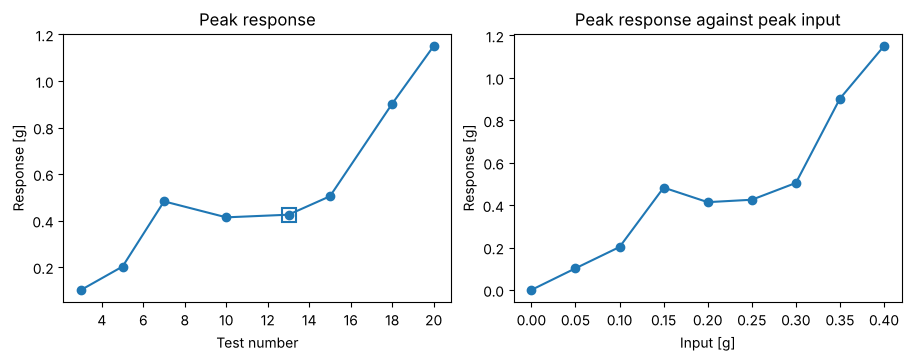

|   number | name    |   Response / Input [g/g] |
|----------|---------|--------------------------|
|        3 | Test 03 |                  2.03908 |
|        5 | Test 05 |                  2.02487 |
|        7 | Test 07 |                  3.21714 |
|       10 | Test 10 |                  2.06962 |
|       13 | Test 13 |                  1.70112 |
|       15 | Test 15 |                  1.68216 |
|       18 | Test 18 |                  2.57857 |
|       20 | Test 20 |                  2.87601 |


In [6]:
# Peak accelerations of the record tests, and response against input
records = camp.select(tags={"record"})
peak_in = records.metric("Input", "max_abs").abs()
peak_out = records.metric("Response", "max_abs").abs()

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
peak_out.plot(ax=axs[0], highlight=13)
peak_out.plot(ax=axs[1], x=peak_in, origin=True)
axs[0].set_title("Peak response")
axs[1].set_title("Peak response against peak input")
plt.show()

print((peak_out / peak_in).to_table())  # amplification, in g/g

Results support transforms such as `.abs()`, `.cumsum()` and arithmetic. Here the residual displacement of each record test (the mean of the last `n_last` samples; `n_last` is a number of samples, not seconds) is accumulated through the campaign. Every plot method returns the `Axes` it drew on, so results go into your own figures with `ax=`.

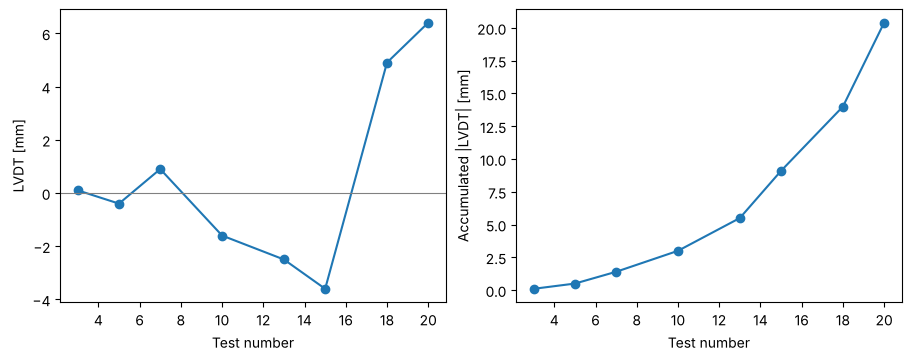

In [7]:
# Residual and accumulated LVDT displacement after each record test
residual = records.metric("LVDT", "residual", n_last=50)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
residual.plot(ax=axs[0])
residual.abs().cumsum().plot(ax=axs[1], ylabel="Accumulated |LVDT| [mm]")
axs[0].axhline(0.0, color="0.5", linewidth=0.8)
plt.show()

## Transfer functions across tests

`transfer_function` returns one curve per test. The default plot overlays the curves, labelled with the real test numbers.

The **heatmap** shows how the resonance moves through the campaign. It is laid out like a spectrogram: test number along the horizontal axis and frequency along the vertical axis, with colour showing the amplitude. Each column is centred on its test number, so the missing test 12 gives a wider column. Because the x-axis is the test number, the result of `peak_frequency` can be drawn on top. The heatmap works best on tests with the same input, here the white-noise tests, so that any change comes from the system.

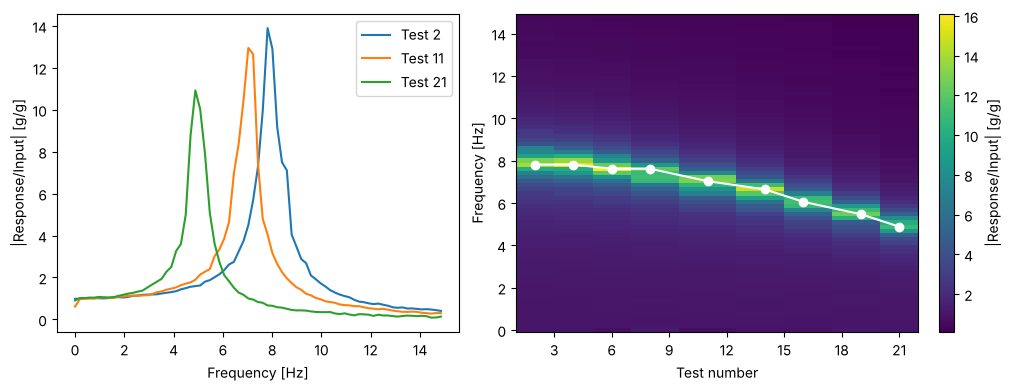

In [8]:
# Overlay of three white-noise tests, and the heatmap of all of them
white_noise = camp.select(tags={"white-noise"})
tf = white_noise.transfer_function("Input", "Response", nperseg=1024)
f_peak = tf.peak_frequency(fmin=2, fmax=15)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
camp.transfer_function("Input", "Response", tests=[2, 11, 21], nperseg=1024).plot(
    ax=axs[0], fmax=15
)
tf.plot(ax=axs[1], kind="heatmap", fmax=15)
f_peak.plot(ax=axs[1], color="w", ylabel="Frequency [Hz]")
plt.show()

`peak_frequency` is an ordinary scalar result, so the drop in natural frequency can be tabulated, exported or plotted like any other metric.

In [9]:
# Natural frequency identified from each white-noise test
print(f_peak.to_table())

|   number | name    |   Peak frequency Response/Input [Hz] |
|----------|---------|--------------------------------------|
|        2 | Test 02 |                               7.8125 |
|        4 | Test 04 |                               7.8125 |
|        6 | Test 06 |                              7.61719 |
|        8 | Test 08 |                              7.61719 |
|       11 | Test 11 |                              7.03125 |
|       14 | Test 14 |                              6.64062 |
|       16 | Test 16 |                              6.05469 |
|       19 | Test 19 |                              5.46875 |
|       21 | Test 21 |                              4.88281 |


## Test-info CSV

The descriptions and tags only need to be typed once. `test_info_to_csv` writes them to a CSV file that can be edited in any spreadsheet program, and `with_test_info_from_csv` reads them back onto freshly loaded tests, matching rows by test number.

In [10]:
# Export the test information, then reload the files and read it back
test_info = os.path.join(folder, "tests.csv")
camp.test_info_to_csv(test_info)

with open(test_info) as f:
    print("".join(f.readlines()[:4]), "...")

reloaded = Campaign.from_folder(
    folder,
    pattern="Sim_*.csv",
    loader=lambda f: Test.from_csv(f).with_channel_info_from_csv(channel_info),
    number_from="Sim_{number}",
).with_test_info_from_csv(test_info)

print("Same names:", reloaded.names == camp.names)
print("Same descriptions:", reloaded.descriptions == camp.descriptions)
print("Same tags:", reloaded.tags == camp.tags)

number,name,description,tags,source_file,csv_n_samples,csv_n_channels,amp
1,Test 01,hammer 0.5 g,"csv,hammer",/tmp/tmp2irhqur6/Sim_001.csv,4000,3,0.5
2,Test 02,white-noise 0.03 g,"csv,white-noise",/tmp/tmp2irhqur6/Sim_002.csv,4000,3,0.03
3,Test 03,record 0.05 g,"csv,record",/tmp/tmp2irhqur6/Sim_003.csv,4000,3,0.05
 ...


Same names: True
Same descriptions: True
Same tags: True


## Checking channels across tests

If a sensor fails or is replaced during a campaign, some tests lack a channel. `check_channels` reports such channels by test number. Here we drop the `LVDT` channel from test 7 to show the report.

In [11]:
# Remove the LVDT from test 7 and check the channels
broken = Campaign.from_tests(
    [t.drop_channels("LVDT") if n == 7 else t for n, t in zip(camp.numbers, camp)],
    numbers=camp.numbers,
    name="Campaign with a missing channel",
)
print(broken.check_channels())
print("\nMissing channels:", broken.missing_channels())

Channel check: Campaign with a missing channel
----------------------------------------------
Channel LVDT: missing in tests 7

Missing channels: {'LVDT': [7]}


A metric of a missing channel gives NaN for that test, with a warning (here caught and printed), so the plot shows a gap instead of failing. Use `strict=True` to raise an error instead.

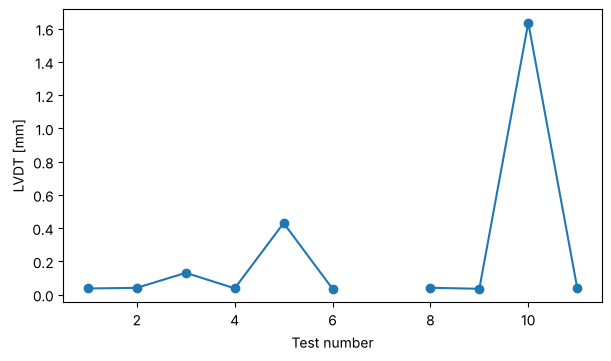

In [12]:
# The missing test shows as a gap in the plot
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    lvdt_peak = broken.select(numbers=range(1, 12)).metric("LVDT", "max_abs").abs()
print("Warning:", caught[0].message)

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
lvdt_peak.plot(ax=ax)
plt.show()

In [13]:
# Remove the temporary folder
tmpdir.cleanup()

## Next steps

- Load your own campaign with `Campaign.from_folder`, passing a `loader` such as `Test.from_sofsi_mat` or a processing chain.
- Keep the test log in a test-info CSV and apply channel-info CSVs to ranges of tests with `with_channel_info_from_csv(..., numbers=range(...))`.
- See the [pyDySP Demo](demo.ipynb) for single-test processing, and the [documentation](https://pydysp.readthedocs.io/en/latest/) for the full API.